In [10]:
#Block 1 : Import Libraries and Read the .csv file
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# Read the CSV file
df = pd.read_csv('../Dataset Creation/mold_dataset_balanced.csv')
df.head()

,date,timestamp,temperature,humidity,light,pressure,mold_risk_category
0,2023-01-01,00:00:00,19.532265,43.395923,268.069537,1014.158334,Low
1,2023-01-01,00:05:00,29.792879,77.162943,361.565517,1010.410460,Moderate
2,2023-01-01,00:10:00,18.588704,76.771950,290.793023,1009.276652,Moderate
3,2023-01-01,00:15:00,21.540002,41.480259,322.553315,1015.095960,Low
4,2023-01-01,00:20:00,25.561456,55.989453,431.299210,1016.551701,Low


In [11]:
# Block 2: Data Exploration
# Basic information about the dataset
print("Dataset Info:")
print(df.info())

print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nData Summary:")
print(df.describe())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210528 entries, 0 to 210527
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   date                210528 non-null  object 
 1   timestamp           210528 non-null  object 
 2   temperature         210528 non-null  float64
 3   humidity            210528 non-null  float64
 4   light               210528 non-null  float64
 5   pressure            210528 non-null  float64
 6   mold_risk_category  210528 non-null  object 
dtypes: float64(4), object(3)
memory usage: 11.2+ MB
None

Dataset Shape: (210528, 7)

Column Names: ['date', 'timestamp', 'temperature', 'humidity', 'light', 'pressure', 'mold_risk_category']

Missing Values:
date                  0
timestamp             0
temperature           0
humidity              0
light                 0
pressure              0
mold_risk_category    0
dtype: int64

Data Summary:
         temperature

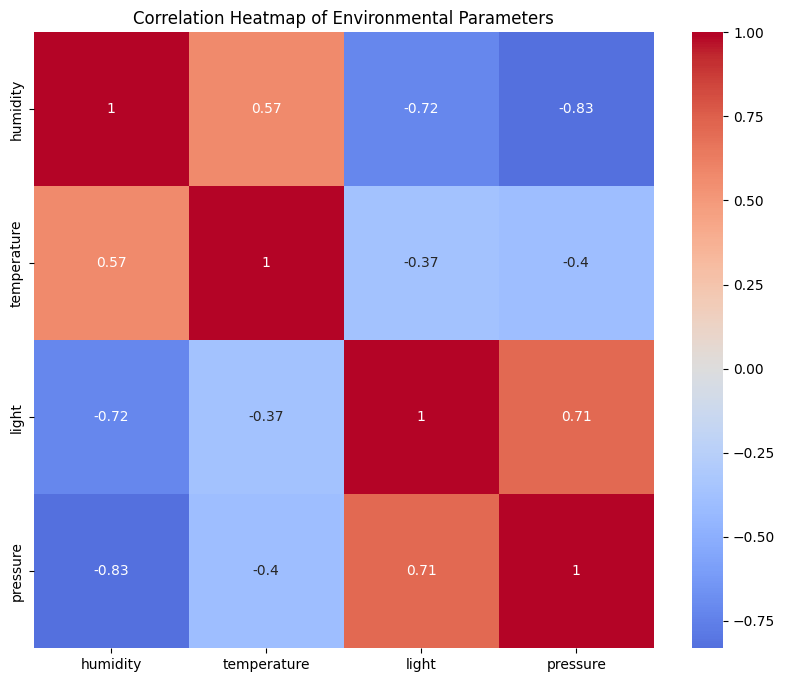

In [12]:
# Block 3: Data Visualization
# Correlation heatmap for specific parameters
selected_columns = ['humidity', 'temperature', 'light', 'pressure']
correlation_matrix_selected = df[selected_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix_selected, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Environmental Parameters')
plt.show()


In [13]:
# Block 4: Statistical Analysis in Table Format
# Create a dictionary to store statistics for each parameter
stats_dict = {}
for column in selected_columns:
    stats = {
        'Minimum': df[column].min(),
        'Maximum': df[column].max(),
        'Range': df[column].max() - df[column].min(),
        'Mean': df[column].mean(),
        'Median': df[column].median(),
        'Mode': df[column].mode().iloc[0],
        'Standard Deviation': df[column].std(),
        'Variance': df[column].var(),
        '25th Percentile': df[column].quantile(0.25),
        '75th Percentile': df[column].quantile(0.75)
    }
    stats_dict[column] = stats

# Convert to DataFrame for better visualization
stats_df = pd.DataFrame(stats_dict)

# Format all numbers to 2 decimal places
stats_df = stats_df.round(2)

# Display the table with parameter names as columns
print("Statistical Analysis of Environmental Parameters:")
print("-" * 80)
print(stats_df)

Statistical Analysis of Environmental Parameters:
--------------------------------------------------------------------------------
                    humidity  temperature     light  pressure
Minimum                31.38        10.01    100.01    990.00
Maximum               100.00        35.00    473.60   1030.00
Range                  68.62        24.99    373.59     40.00
Mean                   70.09        23.67    291.28   1010.82
Median                 71.46        23.69    312.12   1011.48
Mode                   60.00        28.00    100.01    990.00
Standard Deviation     18.78         5.09    101.47      9.77
Variance              352.69        25.89  10296.64     95.51
25th Percentile        52.55        19.89    187.95   1005.00
75th Percentile        87.93        27.60    376.67   1016.51


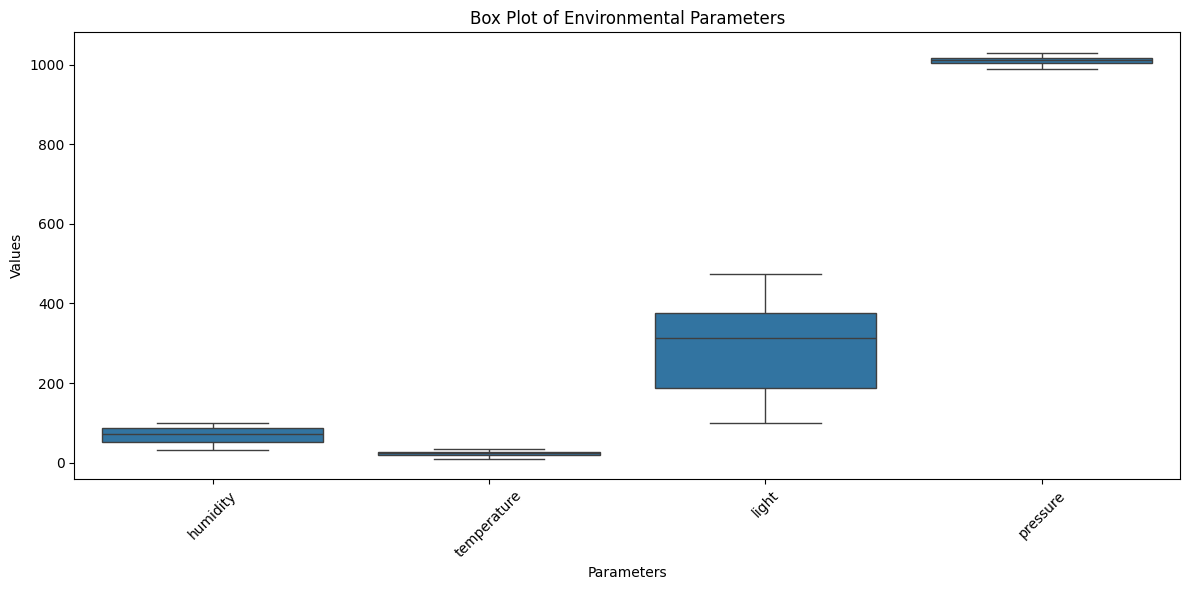

In [14]:
# Block 5: Combined Box Plot Visualization
# Melt the dataframe for combined boxplot
df_melted = df[selected_columns].melt()

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_melted, x='variable', y='value')
plt.title('Box Plot of Environmental Parameters')
plt.xlabel('Parameters')
plt.ylabel('Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

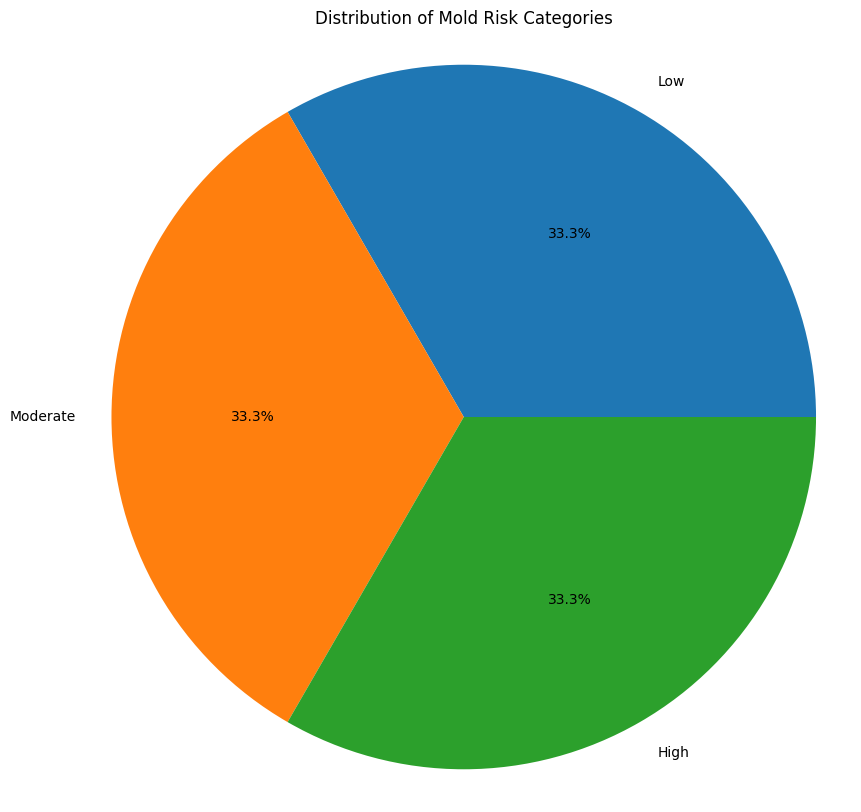


Mold Risk Category Counts:
mold_risk_category
Low         70176
Moderate    70176
High        70176
Name: count, dtype: int64


In [15]:
# Block 6: Mold Risk Category Distribution
plt.figure(figsize=(10, 10))
risk_distribution = df['mold_risk_category'].value_counts()
plt.pie(risk_distribution.values, labels=risk_distribution.index, autopct='%1.1f%%')
plt.title('Distribution of Mold Risk Categories')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle
plt.show()

# Print the exact counts
print("\nMold Risk Category Counts:")
print(risk_distribution)

In [17]:
# Find duplicate rows in the dataset
duplicate_rows = df[df.duplicated()]

print("Number of duplicate rows:", duplicate_rows.shape[0])
print("Duplicate rows (if any):")
print(duplicate_rows)

Number of duplicate rows: 0
Duplicate rows (if any):
Empty DataFrame
Columns: [date, timestamp, temperature, humidity, light, pressure, mold_risk_category]
Index: []


In [16]:
print("Column names in the dataset:")
print(df.columns.tolist())

Column names in the dataset:
['date', 'timestamp', 'temperature', 'humidity', 'light', 'pressure', 'mold_risk_category']
